========== DATASET ==========
    Temperature_C  Humidity_pct  Wind_kmh Play
0              22            45        12   No
1              24            50        15   No
2              25            55        18   No
3              27            60        20  Yes
4              29            65        22  Yes
5              31            70        25  Yes
6              33            75        28  Yes
7              35            80        30  Yes
8              21            40        10   No
9              23            48        13   No
10             26            52        16   No
11             28            58        19  Yes
12             30            62        21  Yes
13             32            68        24  Yes
14             34            72        27  Yes
15             36            78        31  Yes
16             20            42        11   No
17             22            47        14   No
18             24            53        17   No
19             27            5

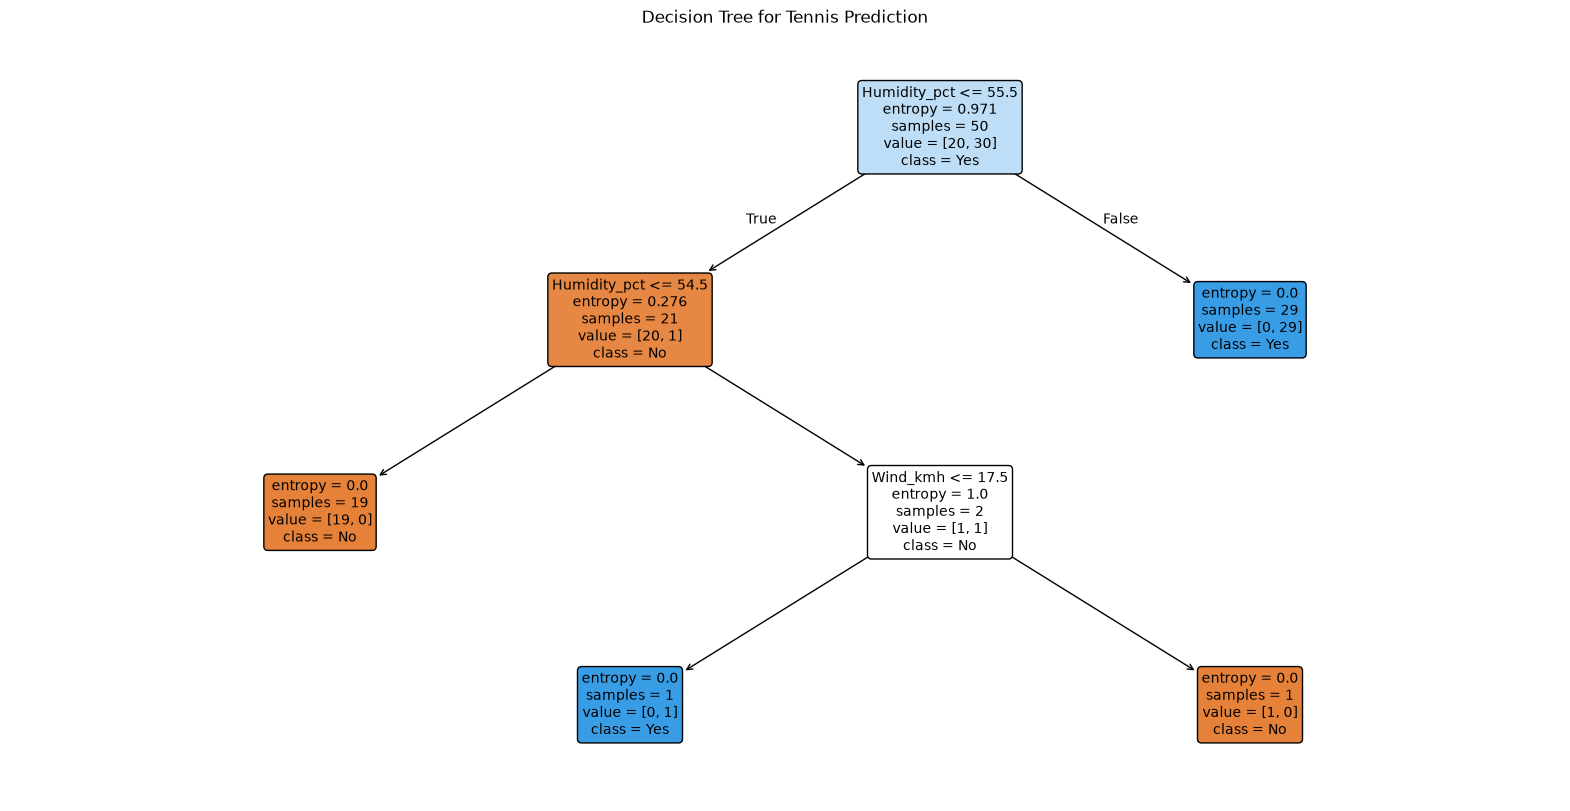


========== DECISION TREE RULES ==========

|--- Humidity_pct <= 55.50
|   |--- Humidity_pct <= 54.50
|   |   |--- class: No
|   |--- Humidity_pct >  54.50
|   |   |--- Wind_kmh <= 17.50
|   |   |   |--- class: Yes
|   |   |--- Wind_kmh >  17.50
|   |   |   |--- class: No
|--- Humidity_pct >  55.50
|   |--- class: Yes


========== PREDICTION ==========
Temperature: 28 °C
Humidity: 62 %
Wind: 16 km/h
Prediction: Yes

========== PREDICTION PROBABILITY ==========
No : 0.0 %
Yes : 100.0 %


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

# ============================================================
# 1. CREATE THE DATASET
# ============================================================

data = {
    'Temperature_C': [
        22,24,25,27,29,31,33,35,21,23,
        26,28,30,32,34,36,20,22,24,27,
        29,31,33,35,19,21,23,26,28,30,
        32,34,18,20,22,25,27,29,31,33,
        17,19,21,24,26,28,30,32,34,36
    ],

    'Humidity_pct': [
        45,50,55,60,65,70,75,80,40,48,
        52,58,62,68,72,78,42,47,53,57,
        63,67,73,77,38,44,49,56,61,66,
        71,76,35,41,46,54,59,64,69,74,
        32,39,43,51,55,60,65,70,75,82
    ],

    'Wind_kmh': [
        12,15,18,20,22,25,28,30,10,13,
        16,19,21,24,27,31,11,14,17,20,
        23,26,29,32,9,12,15,18,21,24,
        27,30,8,10,13,16,19,22,25,28,
        7,9,11,14,17,20,23,26,29,33
    ],

    'Play': [
        'No','No','No','Yes','Yes','Yes','Yes','Yes','No','No',
        'No','Yes','Yes','Yes','Yes','Yes','No','No','No','Yes',
        'Yes','Yes','Yes','Yes','No','No','No','Yes','Yes','Yes',
        'Yes','Yes','No','No','No','No','Yes','Yes','Yes','Yes',
        'No','No','No','No','Yes','Yes','Yes','Yes','Yes','Yes'
    ]
}

df = pd.DataFrame(data)

print("========== DATASET ==========")
print(df)

# ============================================================
# 2. SEPARATE INPUT FEATURES (X) AND TARGET (Y)
# ============================================================

X = df[['Temperature_C', 'Humidity_pct', 'Wind_kmh']]
y = df['Play']

# ============================================================
# 3. CREATE DECISION TREE
# ============================================================

model = DecisionTreeClassifier(
    criterion='entropy',
    random_state=42
)

# ============================================================
# 4. TRAIN THE MODEL
# ============================================================

model.fit(X, y)

# ============================================================
# 5. DISPLAY THE DECISION TREE
# ============================================================

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=model.classes_,
    filled=True,
    rounded=True,
    fontsize=10
)

plt.title("Decision Tree for Tennis Prediction")
plt.show()

# ============================================================
# 6. PRINT THE DECISION TREE RULES / KEYS
# ============================================================

print("\n========== DECISION TREE RULES ==========\n")

rules = export_text(
    model,
    feature_names=list(X.columns)
)

print(rules)

# ============================================================
# 7. PREDICT FOR A NEW DATA SAMPLE
# ============================================================

# Change these values to test different inputs

new_data = pd.DataFrame({
    'Temperature_C': [28],
    'Humidity_pct': [62],
    'Wind_kmh': [16]
})

prediction = model.predict(new_data)

print("\n========== PREDICTION ==========")

print("Temperature:", new_data['Temperature_C'].iloc[0], "°C")
print("Humidity:", new_data['Humidity_pct'].iloc[0], "%")
print("Wind:", new_data['Wind_kmh'].iloc[0], "km/h")

print("Prediction:", prediction[0])

# ============================================================
# 8. SHOW PREDICTION PROBABILITY
# ============================================================

probability = model.predict_proba(new_data)

print("\n========== PREDICTION PROBABILITY ==========")

for class_name, prob in zip(model.classes_, probability[0]):
    print(class_name, ":", round(prob * 100, 2), "%")